revenue questions


1What is the monthly revenue, and how much did it grow month over month?


q2Which 10 product categories earn the most?


q3Which states have the highest total revenue and highest average order value?

q6What is the payment method mix, and how many installments does each method use on average?

q8Which sellers earn the most

q10What share of total revenue comes from the top 10% of customers?


In [98]:
import pandas as pd
import matplotlib.pyplot as plt

In [99]:
orders = pd.read_csv('olist_orders_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers= pd.read_csv("olist_sellers_dataset.csv")

In [100]:
#monthly revue and how much did it grow over month
delivered_orders = orders[orders["order_status"] == "delivered"]['order_id']
print(payments[
    payments["order_id"].isin(delivered_orders)
])
#order id ,customer id,ordedrstatus==delivered,purchasetimestamp,
#1) HAVE TO CHECK WHY ARE ORDERID REPEATING IN PAYMENTS
duplicated = payments[payments['order_id'].duplicated(keep= False)]['order_id']
print(payments[
    payments["order_id"].isin(duplicated)
])
###some customers have paid total amount in split terms

                                order_id  payment_sequential payment_type  \
0       b81ef226f3fe1789b1e8b2acac839d17                   1  credit_card   
1       a9810da82917af2d9aefd1278f1dcfa0                   1  credit_card   
2       25e8ea4e93396b6fa0d3dd708e76c1bd                   1  credit_card   
3       ba78997921bbcdc1373bb41e913ab953                   1  credit_card   
4       42fdf880ba16b47b59251dd489d4441a                   1  credit_card   
...                                  ...                 ...          ...   
103879  c45067032fd84f4cf408730ff5205568                   1  credit_card   
103881  0406037ad97740d563a178ecc7a2075c                   1       boleto   
103882  7b905861d7c825891d6347454ea7863f                   1  credit_card   
103884  b8b61059626efa996a60be9bb9320e10                   1  credit_card   
103885  28bbae6599b09d39ca406b747b6632b1                   1       boleto   

        payment_installments  payment_value  
0                          8 

In [101]:
##adding up the value for each order id 
paymentsds = payments.groupby("order_id",as_index=False)["payment_value"].sum()
paymentsds = paymentsds.rename(
    columns={"payment_value": "order_total"}
)
print(paymentsds.info())
 

<class 'pandas.DataFrame'>
RangeIndex: 99440 entries, 0 to 99439
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   order_id     99440 non-null  str    
 1   order_total  99440 non-null  float64
dtypes: float64(1), str(1)
memory usage: 1.5 MB
None


monthly revenue trend with and without delivered orders


In [102]:
##merging and making new order column
order_new = orders.merge(
    paymentsds,
    on= 'order_id',
    how='outer'
)
print(order_new.info())
#convertin str to dattime
order_new["order_purchase_timestamp"] = pd.to_datetime(order_new["order_purchase_timestamp"])
order_new["order_approved_at"] = pd.to_datetime(order_new["order_approved_at"])
order_new["order_delivered_carrier_date"] = pd.to_datetime(order_new["order_delivered_carrier_date"])
order_new["order_delivered_customer_date"] = pd.to_datetime(order_new["order_delivered_customer_date"])
order_new["order_estimated_delivery_date"] = pd.to_datetime(order_new["order_estimated_delivery_date"])
#sorting values acc to their dates and grouping them into year month  and finding month wise revenue
order_new = order_new.sort_values('order_purchase_timestamp')
revenue = order_new.groupby([
    order_new["order_purchase_timestamp"].dt.year.rename("year"),
    order_new["order_purchase_timestamp"].dt.month.rename("month")
])["order_total"].sum()
##finding growth of revenue month wise
monthwisegrowth = ((revenue - revenue.shift(1))/revenue.shift(1)) * 100
print(monthwisegrowth)


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       99441 non-null  str    
 1   customer_id                    99441 non-null  str    
 2   order_status                   99441 non-null  str    
 3   order_purchase_timestamp       99441 non-null  str    
 4   order_approved_at              99281 non-null  str    
 5   order_delivered_carrier_date   97658 non-null  str    
 6   order_delivered_customer_date  96476 non-null  str    
 7   order_estimated_delivery_date  99441 non-null  str    
 8   order_total                    99440 non-null  float64
dtypes: float64(1), str(8)
memory usage: 6.8 MB
None
year  month
2016  9                  NaN
      10        23326.292420
      12          -99.966797
2017  1        705751.376147
      2           110.782108
      3            54.111427
    

In [103]:
##making presentable
growth_df = monthwisegrowth.reset_index(name="growth_pct")
monthly_df = revenue.reset_index()
monthly_df = monthly_df.merge(growth_df, on=["year", "month"])
print(monthly_df)
display = monthly_df.round(2)
display['date'] = pd.to_datetime({
    'year': display['year'],
    'month': display['month'],
    'day': 1
})
display.head()

    year  month  order_total     growth_pct
0   2016      9       252.24            NaN
1   2016     10     59090.48   23326.292420
2   2016     12        19.62     -99.966797
3   2017      1    138488.04  705751.376147
4   2017      2    291908.01     110.782108
5   2017      3    449863.60      54.111427
6   2017      4    417788.03      -7.130066
7   2017      5    592918.82      41.918575
8   2017      6    511276.38     -13.769581
9   2017      7    592382.92      15.863541
10  2017      8    674396.32      13.844660
11  2017      9    727762.45       7.913170
12  2017     10    779677.88       7.133568
13  2017     11   1194882.80      53.253392
14  2017     12    878401.48     -26.486390
15  2018      1   1115004.18      26.935599
16  2018      2    992463.34     -10.990169
17  2018      3   1159652.12      16.845839
18  2018      4   1160785.48       0.097733
19  2018      5   1153982.15      -0.586097
20  2018      6   1023880.50     -11.274148
21  2018      7   1066540.75    

,year,month,order_total,growth_pct,date
0,2016,9,252.24,NaN,2016-09-01
1,2016,10,59090.48,23326.29,2016-10-01
2,2016,12,19.62,-99.97,2016-12-01
3,2017,1,138488.04,705751.38,2017-01-01
4,2017,2,291908.01,110.78,2017-02-01


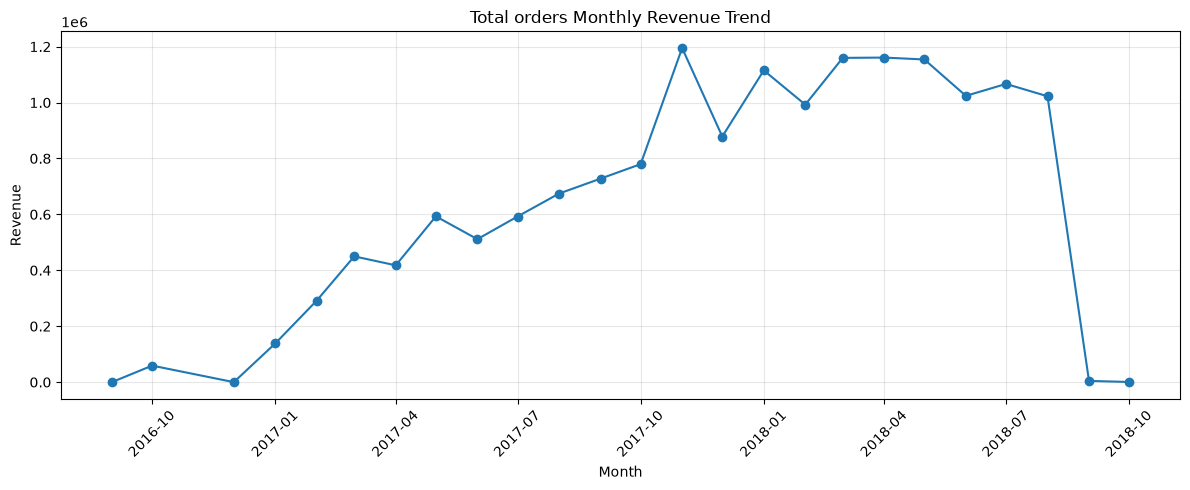

In [104]:

# chart size
plt.figure(figsize=(12, 5))
#line chart
plt.plot(display['date'], display['order_total'], marker='o')
#  labels and title
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.title('Total orders Monthly Revenue Trend')
#Rotate date labels
plt.xticks(rotation=45)
# grid
plt.grid(True, alpha=0.3)
# layout and display
plt.tight_layout()
plt.show()

In [105]:
 ##only delivered orders
delivered_orders = order_new[order_new['order_status']=='delivered']
##grouping
deliveredorders_revenue =  delivered_orders.groupby([delivered_orders['order_purchase_timestamp'].dt.year.rename('year'),delivered_orders['order_purchase_timestamp'].dt.month.rename('month')])['order_total'].sum()
##finding % wise growth
growthinpercent =  ((deliveredorders_revenue-deliveredorders_revenue.shift(1))/deliveredorders_revenue.shift(1)) * 100
print(growthinpercent)

year  month
2016  9                 NaN
      10                inf
      12      -9.995787e+01
2017  1        6.499799e+05
      2        1.127071e+02
      3        5.273551e+01
      4       -5.651289e+00
      5        4.504759e+01
      6       -1.355063e+01
      7        1.553944e+01
      8        1.405299e+01
      9        8.540144e+00
      10       7.126700e+00
      11       5.357026e+01
      12      -2.690259e+01
2018  1        2.791840e+01
      2       -1.039266e+01
      3        1.595089e+01
      4        1.093619e+00
      5       -3.616504e-01
      6       -1.034215e+01
      7        1.562427e+00
      8       -4.133614e+00
Name: order_total, dtype: float64


In [106]:
#making presentable
growth_pe = growthinpercent.reset_index(name= "growth percentage")
monthly = deliveredorders_revenue.reset_index()
growth_pe = growth_pe.merge(monthly,on=["year", "month"])
print(growth_pe)

    year  month  growth percentage  order_total
0   2016      9                NaN         0.00
1   2016     10                inf     46566.71
2   2016     12      -9.995787e+01        19.62
3   2017      1       6.499799e+05    127545.67
4   2017      2       1.127071e+02    271298.65
5   2017      3       5.273551e+01    414369.39
6   2017      4      -5.651289e+00    390952.18
7   2017      5       4.504759e+01    567066.73
8   2017      6      -1.355063e+01    490225.60
9   2017      7       1.553944e+01    566403.93
10  2017      8       1.405299e+01    646000.61
11  2017      9       8.540144e+00    701169.99
12  2017     10       7.126700e+00    751140.27
13  2017     11       5.357026e+01   1153528.05
14  2017     12      -2.690259e+01    843199.17
15  2018      1       2.791840e+01   1078606.86
16  2018      2      -1.039266e+01    966510.88
17  2018      3       1.595089e+01   1120678.00
18  2018      4       1.093619e+00   1132933.95
19  2018      5      -3.616504e-01   112

Top 10 product
 categories with most revenue
 
 Top 10 categories by items sold 



In [107]:
print(order_items['order_id'].nunique())
print(delivered_orders['order_id'].count())
print(order_new['order_id'].count())
###order items exclude 775 orders from order_items
#########merging product id with category
idandcategory = order_items.merge(products[['product_id','product_category_name']],on='product_id',how='left')
#top 10 categories with highest revenue
category_revenue = idandcategory.groupby('product_category_name')['price'].sum().sort_values(ascending=False)
#TOP 10 PRODUCT CATEGORIES WITH MOST REVENUE
print(category_revenue)
###top 10 CATEGORIES SOLD
top_categories_by_orders = (
    idandcategory.groupby('product_category_name')['order_id']
    .nunique()
    .nlargest(10)
)

print(top_categories_by_orders)

98666
96478
99441
product_category_name
beleza_saude                     1258681.34
relogios_presentes               1205005.68
cama_mesa_banho                  1036988.68
esporte_lazer                     988048.97
informatica_acessorios            911954.32
                                    ...    
flores                              1110.04
casa_conforto_2                      760.27
cds_dvds_musicais                    730.00
fashion_roupa_infanto_juvenil        569.85
seguros_e_servicos                   283.29
Name: price, Length: 73, dtype: float64
product_category_name
cama_mesa_banho           9417
beleza_saude              8836
esporte_lazer             7720
informatica_acessorios    6689
moveis_decoracao          6449
utilidades_domesticas     5884
relogios_presentes        5624
telefonia                 4199
automotivo                3897
brinquedos                3886
Name: order_id, dtype: int64


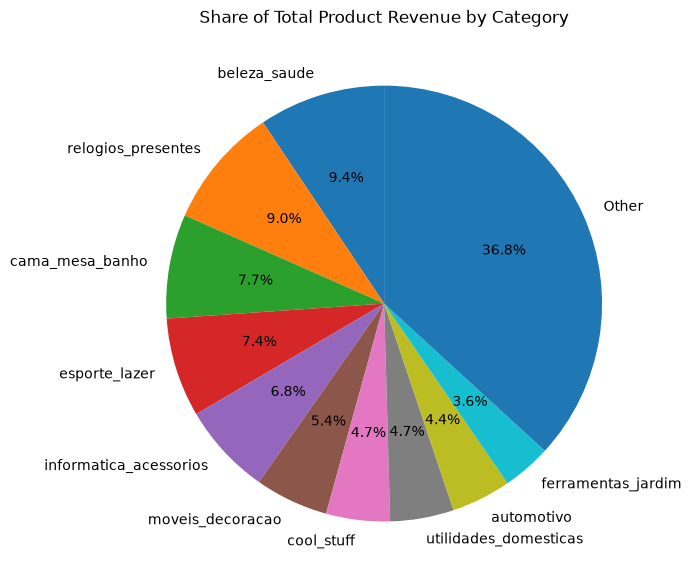

In [111]:
###chart
top_10 = category_revenue.head(10)

other = category_revenue.iloc[10:].sum()

chart_data = pd.concat([
    top_10,
    pd.Series({'Other': other})
])
chart_data.plot(
    kind='pie',
    figsize=(7,7),
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Share of Total Product Revenue by Category')
plt.ylabel('')
plt.tight_layout()
plt.show()